# Customer churn: EDA, models and evaluation

End-to-end walkthrough of the project. The data is **synthetic** (generated in `ml_intern.data`), so the numbers show that the pipeline works, not how a real telecom dataset would behave.

Run the cells from top to bottom. Outputs are saved, so the charts are visible on GitHub without running anything.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Works whether Jupyter was started in the repo root or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import joblib
import matplotlib.pyplot as plt
import pandas as pd

from ml_intern.data import load_or_create
from ml_intern.report import plot_confusion, plot_importance, plot_roc
from ml_intern.train import MODEL_DIR, split_data, train

df = load_or_create()
df.head()

,tenure_months,monthly_charges,support_tickets,contract_type,uses_addon,churned
0,7,92.45,2,month-to-month,1,1
1,56,59.44,0,month-to-month,0,0
2,48,73.00,2,two-year,0,0
3,32,18.00,1,two-year,0,0
4,32,39.56,2,month-to-month,1,0


## 2. Explore the data

In [2]:
df.describe(include="all")

,tenure_months,monthly_charges,support_tickets,contract_type,uses_addon,churned
count,1200.000000,1200.000000,1200.000000,1200,1200.000000,1200.000000
unique,NaN,NaN,NaN,3,NaN,NaN
top,NaN,NaN,NaN,month-to-month,NaN,NaN
freq,NaN,NaN,NaN,677,NaN,NaN
mean,36.823333,64.105575,1.359167,NaN,0.481667,0.365000
std,20.712548,22.063045,1.196394,NaN,0.499872,0.481631
min,1.000000,18.000000,0.000000,NaN,0.000000,0.000000
25%,19.000000,49.285000,0.000000,NaN,0.000000,0.000000
50%,37.000000,64.665000,1.000000,NaN,0.000000,0.000000
75%,55.000000,78.542500,2.000000,NaN,1.000000,1.000000


In [3]:
print("rows:", len(df), "| churn rate:", round(df["churned"].mean(), 3))
df.groupby("contract_type")["churned"].mean().round(3).sort_values()

rows: 1200 | churn rate: 0.365


contract_type
two-year          0.185
one-year          0.304
month-to-month    0.445
Name: churned, dtype: float64

Month-to-month customers churn far more often than customers on one- or two-year contracts.

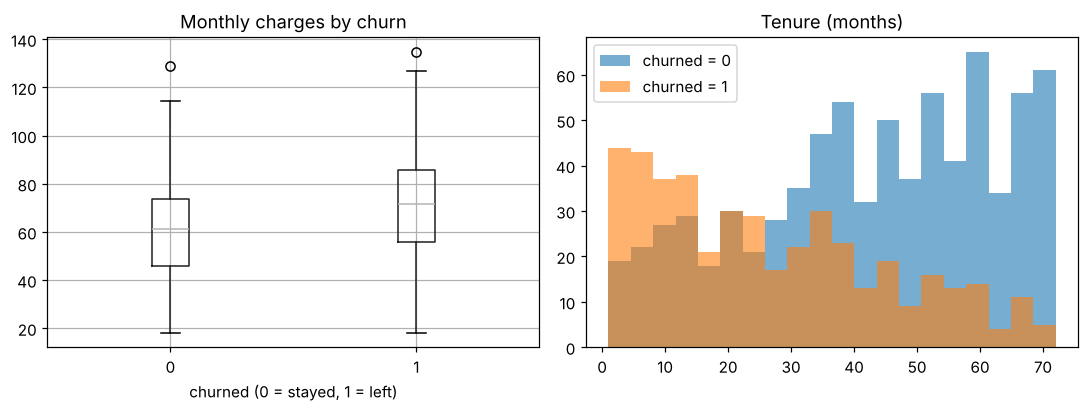

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

df.boxplot(column="monthly_charges", by="churned", ax=axes[0])
axes[0].set_title("Monthly charges by churn")
axes[0].set_xlabel("churned (0 = stayed, 1 = left)")

for label, group in df.groupby("churned"):
    axes[1].hist(group["tenure_months"], bins=20, alpha=0.6, label=f"churned = {label}")
axes[1].set_title("Tenure (months)")
axes[1].legend()

fig.suptitle("")
fig.tight_layout()

## 3. Train and compare models

`train()` fits a logistic regression baseline and a random forest on an 80/20 stratified split, keeps the one with the higher holdout ROC-AUC, and saves it. It also runs 5-fold cross-validation, because a 240-row holdout set is noisy.

In [5]:
summary = train()
print("best model:", summary["best_model"])
pd.DataFrame(summary["metrics"]).T

best model: logreg


,accuracy,precision,recall,f1,roc_auc
logreg,0.7000,0.5741,0.7045,0.6327,0.7882
random_forest,0.7208,0.6019,0.7045,0.6492,0.7710


In [6]:
pd.DataFrame(summary["cv_roc_auc"]).T.rename(columns={"mean": "cv_roc_auc_mean", "std": "cv_roc_auc_std"})

,cv_roc_auc_mean,cv_roc_auc_std
logreg,0.7991,0.0221
random_forest,0.7714,0.0246


The two models are close: the gap between them is about the same size as the fold-to-fold spread, so the choice of logistic regression is weakly supported. A simple, explainable model is a sensible default here.

## 4. Evaluate

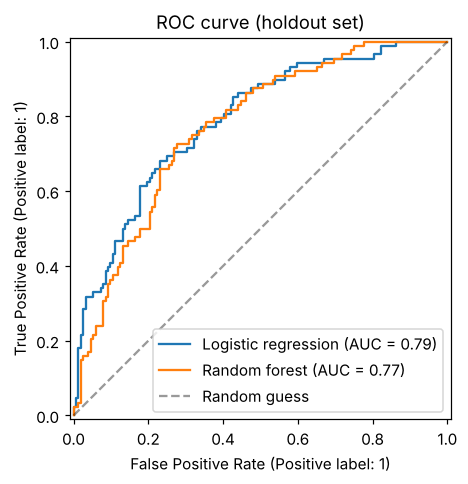

In [7]:
df = load_or_create()
x_train, x_test, y_train, y_test = split_data(df)
best = joblib.load(MODEL_DIR / "churn_model.joblib")
fig = plot_roc(x_train, y_train, x_test, y_test)

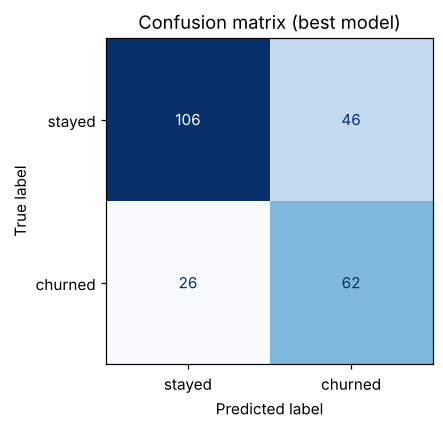

In [8]:
fig = plot_confusion(best, x_test, y_test)

The model catches about 70% of customers who churn (recall), but about 4 in 10 customers it flags actually stay (precision), so a retention campaign based on it would contact some customers unnecessarily.

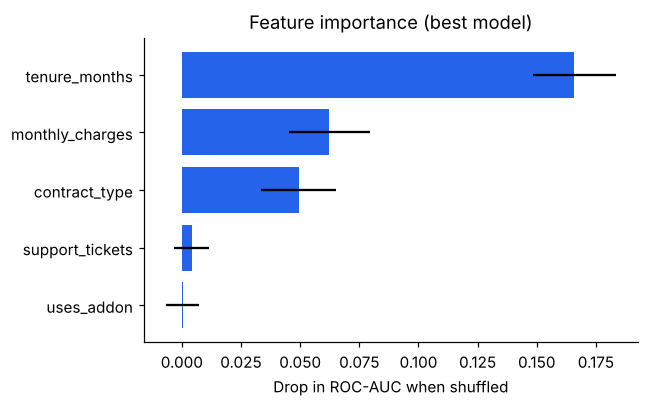

In [9]:
fig = plot_importance(best, x_test, y_test)

Tenure matters most, then monthly charges and contract type. This matches how the data was generated (`ml_intern.data`), so it is a sanity check, not a discovery.